# Modul

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import RandomOverSampler
from scipy.stats import norm
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import SMOTE

import seaborn as sns
import matplotlib.pyplot as plt
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/FauzanTrisuladana/content/refs/heads/master/healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


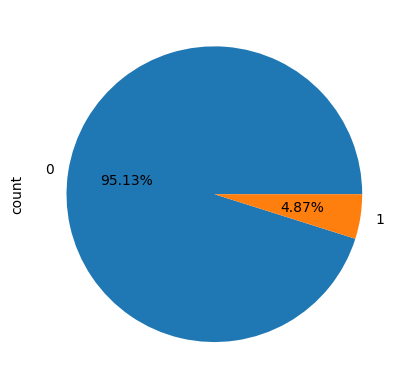

In [ ]:
# dustribusi data
data = df['stroke'].value_counts()
data.plot(kind='pie', autopct='%.2f%%')
plt.show()

In [ ]:
# imputasi missing value
df['bmi'].fillna(df['bmi'].mean(), inplace=True)

/tmp/ipykernel_2825/3428042051.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bmi'].fillna(df['bmi'].mean(), inplace=True)


In [ ]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [ ]:
under_sampling = RandomUnderSampler(random_state=0)
df_X = df.drop(['id', 'stroke'], axis=1)
df_y = df['stroke']

le = LabelEncoder()
df_y = le.fit_transform(df_y)

# imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'])
df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
df_X['work_type'] = le.fit_transform(df_X['work_type'])
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

X = df_X.astype(float).values
y = df_y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

X_resampled, y_resampled = under_sampling.fit_resample(X_train, y_train)

print('sebelum undersampling')
print(pd.DataFrame(y_train).value_counts())
print('setelah undersampling')
print(pd.DataFrame(y_resampled).value_counts())

sebelum undersampling
0
0    3663
1     169
Name: count, dtype: int64
setelah undersampling
0
0    169
1    169
Name: count, dtype: int64


In [ ]:
# menampilkan kolom stroke
df_y = df['stroke']
df_y

,stroke
0,1
1,1
2,1
3,1
4,1
...,...
5105,0
5106,0
5107,0
5108,0


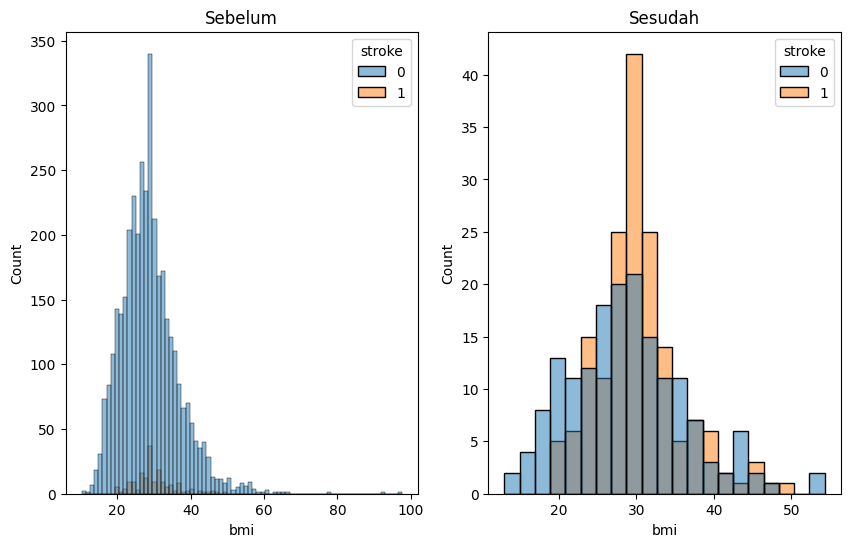

In [ ]:
dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks(rotation='horizontal')
plt.show()

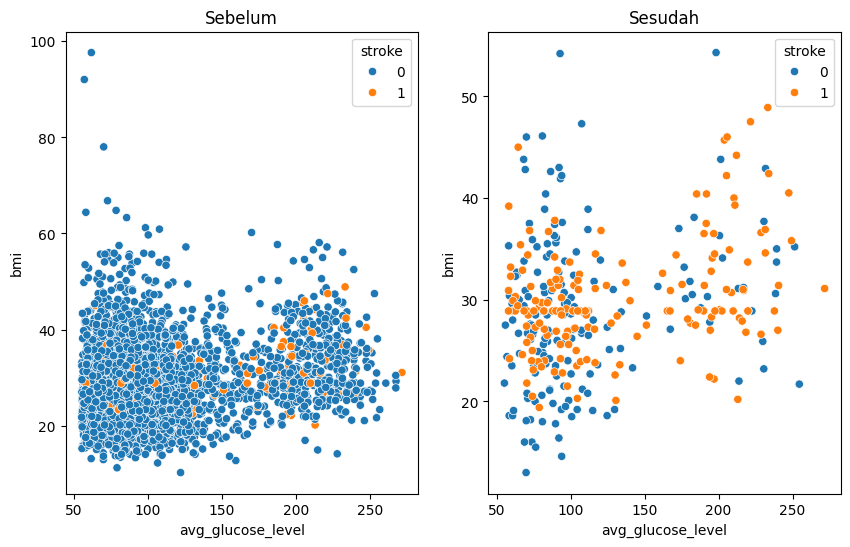

In [ ]:
f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

In [ ]:
over_sampling = RandomOverSampler(random_state=0)
df_X = df.drop(['id', 'stroke'], axis=1)
df_y = df['stroke']

# imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'])
df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
df_X['work_type'] = le.fit_transform(df_X['work_type'])
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

X = df_X.astype(float).values
y = df_y.astype(float).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

X_resampled, y_resampled = over_sampling.fit_resample(X_train, y_train)

print('sebelum random oversampling')
print(pd.DataFrame(y_train).value_counts())
print('setelah random oversampling')
print(pd.DataFrame(y_resampled).value_counts())

sebelum random oversampling
0  
0.0    3663
1.0     169
Name: count, dtype: int64
setelah random oversampling
0  
0.0    3663
1.0    3663
Name: count, dtype: int64


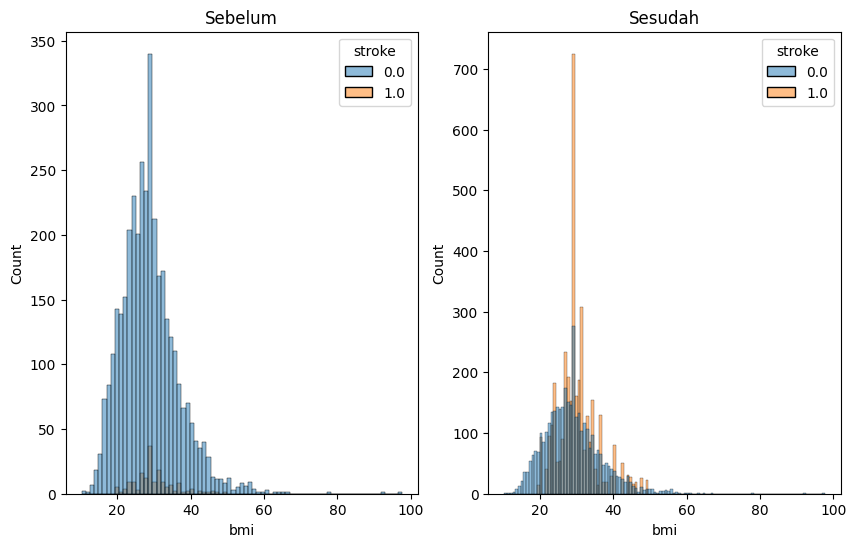

In [ ]:
dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

In [ ]:
df_X = df.drop(['id','stroke'],axis=1)
df_y = df['stroke']

# imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

#categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'])
df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
df_X['work_type'] = le.fit_transform(df_X['work_type'])
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

X = df_X.astype(float).values
y = df_y.astype(float).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
smote = SMOTE(random_state=0)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

print('Sebelum SMOTE')
print(pd.DataFrame(y_train).value_counts())
print('Setelah SMOTE')
print(pd.DataFrame(y_resampled).value_counts())

Sebelum SMOTE
0  
0.0    3663
1.0     169
Name: count, dtype: int64
Setelah SMOTE
0  
0.0    3663
1.0    3663
Name: count, dtype: int64


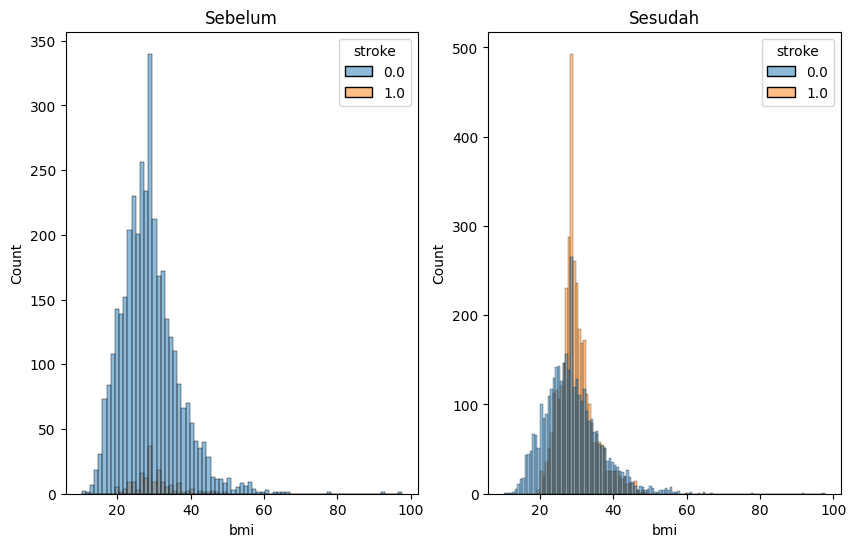

In [ ]:
dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

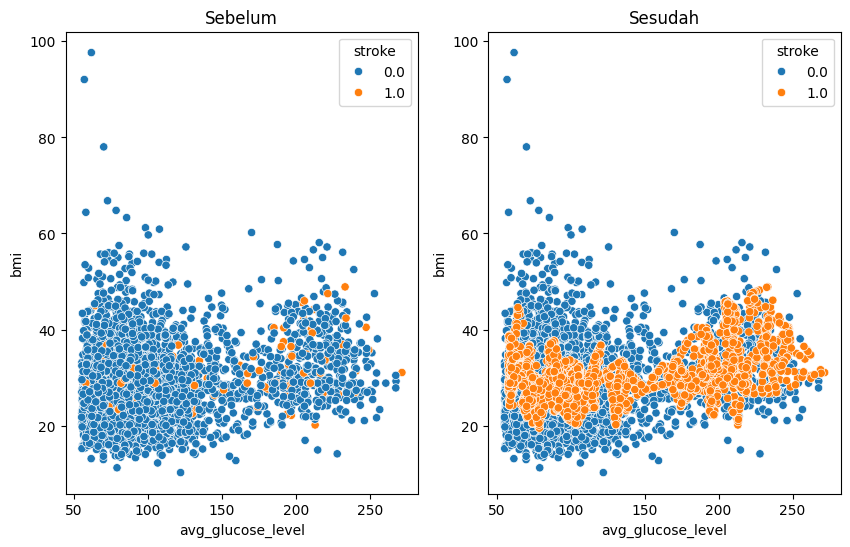

In [ ]:
f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

In [ ]:
df_X = df.drop(['id','stroke'],axis=1)
df_y = df['stroke']

# imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'])
df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
df_X['work_type'] = le.fit_transform(df_X['work_type'])
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

X = df_X.astype(float).values
y = df_y.astype(float).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
adasyn = ADASYN(random_state=0)
X_resampled, y_resampled = adasyn.fit_resample(X_train, y_train)

print('Sebelum ADASYN')
print(pd.DataFrame(y_train).value_counts())
print('Setelah ADASYN')
print(pd.DataFrame(y_resampled).value_counts())

Sebelum ADASYN
0  
0.0    3663
1.0     169
Name: count, dtype: int64
Setelah ADASYN
0  
1.0    3676
0.0    3663
Name: count, dtype: int64


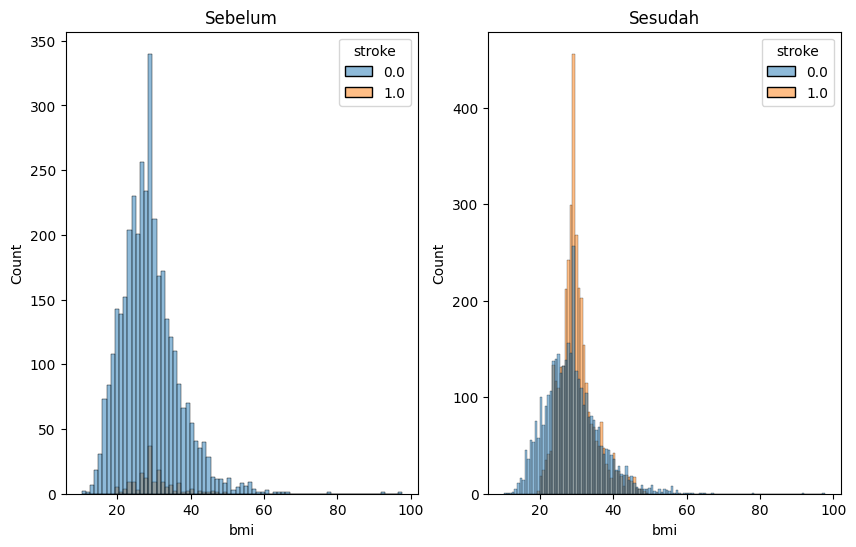

In [ ]:
dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

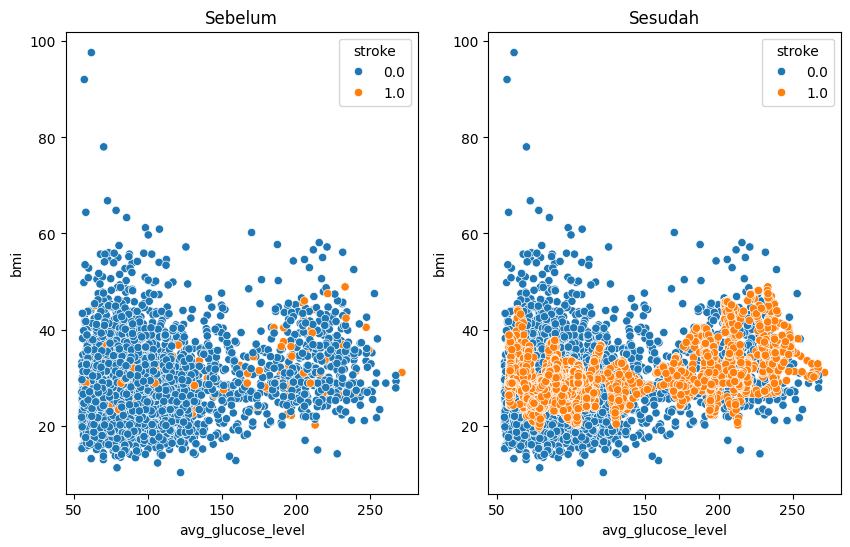

In [ ]:
f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

# Tugas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/FauzanTrisuladana/content/refs/heads/master/ocupancy_dataset.csv')
df

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
140,2015-02-02 14:19:00,23.7000,26.2720,585.200000,749.200000,0.004764,1
141,2015-02-02 14:19:59,23.7180,26.2900,578.400000,760.400000,0.004773,1
142,2015-02-02 14:21:00,23.7300,26.2300,572.666667,769.666667,0.004765,1
143,2015-02-02 14:22:00,23.7225,26.1250,493.750000,774.750000,0.004744,1
144,2015-02-02 14:23:00,23.7540,26.2000,488.600000,779.000000,0.004767,1
...,...,...,...,...,...,...,...
9748,2015-02-18 09:15:00,20.8150,27.7175,429.750000,1505.250000,0.004213,1
9749,2015-02-18 09:16:00,20.8650,27.7450,423.500000,1514.500000,0.004230,1
9750,2015-02-18 09:16:59,20.8900,27.7450,423.500000,1521.500000,0.004237,1
9751,2015-02-18 09:17:59,20.8900,28.0225,418.750000,1632.000000,0.004279,1


In [ ]:
df.describe()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031
std,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000
50%,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000
75%,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000
max,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000


In [ ]:
df.corr(numeric_only=True)

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
Temperature,1.000000,-0.156964,0.688571,0.449989,0.205280,0.555610
Humidity,-0.156964,1.000000,-0.029459,0.299746,0.932724,0.046240
Light,0.688571,-0.029459,1.000000,0.448105,0.223329,0.914850
CO2,0.449989,0.299746,0.448105,1.000000,0.477965,0.501582
HumidityRatio,0.205280,0.932724,0.223329,0.477965,1.000000,0.257324
Occupancy,0.555610,0.046240,0.914850,0.501582,0.257324,1.000000


In [ ]:
df.isnull().sum()

,0
date,0
Temperature,0
Humidity,0
Light,0
CO2,0
HumidityRatio,0
Occupancy,0


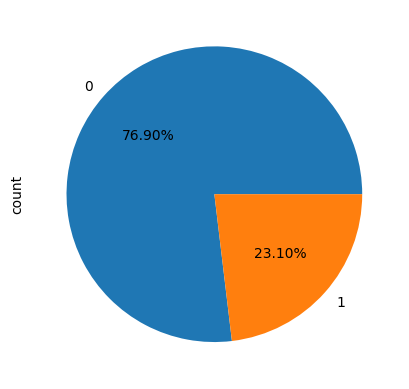

In [ ]:
data = df['Occupancy'].value_counts()
data.plot(kind='pie', autopct='%.2f%%')
plt.show()

In [ ]:
df_X = df.drop(['date', 'Occupancy'], axis=1)
df_y = df['Occupancy']

cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index([], dtype='object')


In [ ]:
df_X

,Temperature,Humidity,Light,CO2,HumidityRatio
140,23.7000,26.2720,585.200000,749.200000,0.004764
141,23.7180,26.2900,578.400000,760.400000,0.004773
142,23.7300,26.2300,572.666667,769.666667,0.004765
143,23.7225,26.1250,493.750000,774.750000,0.004744
144,23.7540,26.2000,488.600000,779.000000,0.004767
...,...,...,...,...,...
9748,20.8150,27.7175,429.750000,1505.250000,0.004213
9749,20.8650,27.7450,423.500000,1514.500000,0.004230
9750,20.8900,27.7450,423.500000,1521.500000,0.004237
9751,20.8900,28.0225,418.750000,1632.000000,0.004279


In [ ]:
df_y

,Occupancy
140,1
141,1
142,1
143,1
144,1
...,...
9748,1
9749,1
9750,1
9751,1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3, random_state=8)

#scaling
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
X_train

array([[ 0.37308189,  0.81737217, -0.47165892, -0.08251677,  0.96916783],
       [-1.18664894,  1.75969382, -0.61893268, -0.61978609,  1.21447063],
       [ 2.18959767,  0.20751682,  1.58542301,  1.43627143,  1.07051653],
       ...,
       [-0.18804079, -0.53352252, -0.61893268, -0.63021072, -0.59332657],
       [-0.53042073,  0.50793818, -0.61893268,  0.10833412,  0.30123511],
       [-0.62077099, -1.3947304 , -0.61893268, -0.81544835, -1.55206684]])

In [ ]:
X_test

array([[-0.75867402,  0.92652526, -0.61893268, -0.37921774,  0.61302508],
       [-0.1452433 ,  1.38717134, -0.4312774 , -0.61337093,  1.31901259],
       [ 0.37308189,  0.0252612 , -0.61893268,  0.29437365,  0.15907924],
       ...,
       [-0.28314633,  0.54599155, -0.61893268,  0.31041154,  0.43285248],
       [-0.28314633,  0.06732019, -0.61893268, -0.65186187, -0.03592407],
       [ 0.73923821,  0.26209337,  1.53791534,  0.7113588 ,  0.54266507]])

In [ ]:
y_train

,Occupancy
5845,0
3660,0
222,1
6261,0
2786,0
...,...
4331,0
7712,0
2321,0
7610,0


In [ ]:
y_test

,Occupancy
5231,0
4230,0
1914,0
2295,0
7627,0
...,...
2670,1
314,0
8244,0
454,0


## Sebelum Smote

Accuracy  0.9907587548638133
Precision  0.9855285984643565
Recall  0.9886049356451442
Confusion matrix  [[4705   35]
 [  22 1406]]


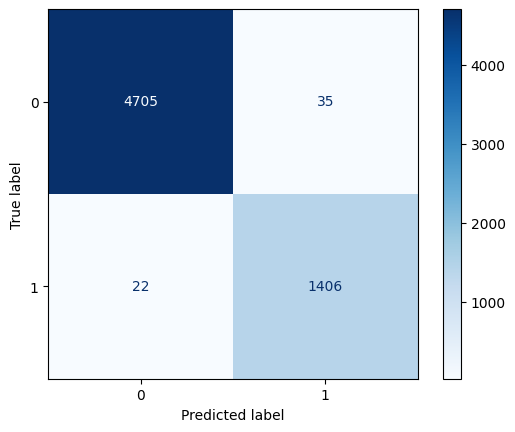

In [ ]:
model=RandomForestClassifier()
model.fit(X_train, y_train)

# membuat prediksi
y_pred = model.predict(X_test)

#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# plt.show()
disp.plot(cmap=plt.cm.Blues)

## Setelah Smote

In [ ]:
from imblearn.over_sampling import SMOTE
from scipy.stats import norm
import os
import seaborn as sns

In [ ]:
smote = SMOTE(random_state=0)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

print('Sebelum SMOTE')
print(pd.DataFrame(y_train).value_counts())
print('Setelah SMOTE')
print(pd.DataFrame(y_resampled).value_counts())

Sebelum SMOTE
Occupancy
0            11070
1             3322
Name: count, dtype: int64
Setelah SMOTE
Occupancy
0            11070
1            11070
Name: count, dtype: int64


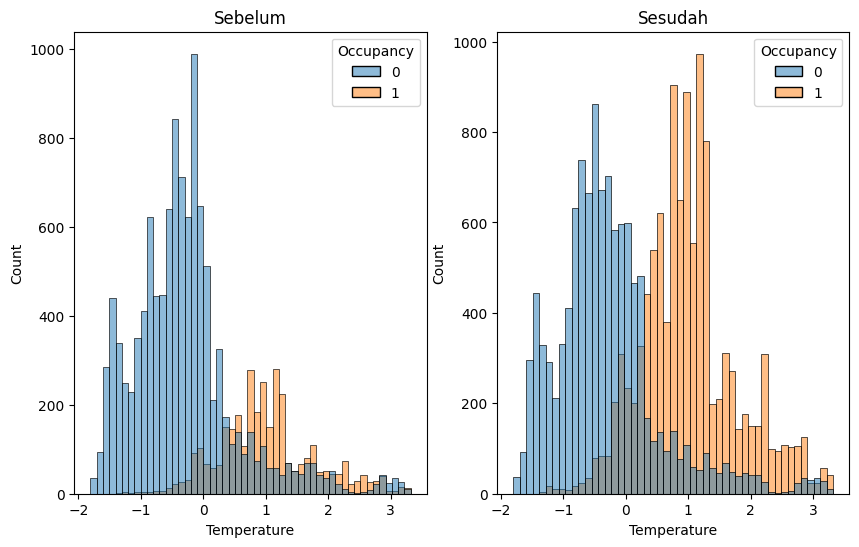

In [ ]:
dfx_ori = pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train.values, columns=['Occupancy'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled.values, columns=['Occupancy'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='Temperature', hue='Occupancy', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='Temperature', hue='Occupancy', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

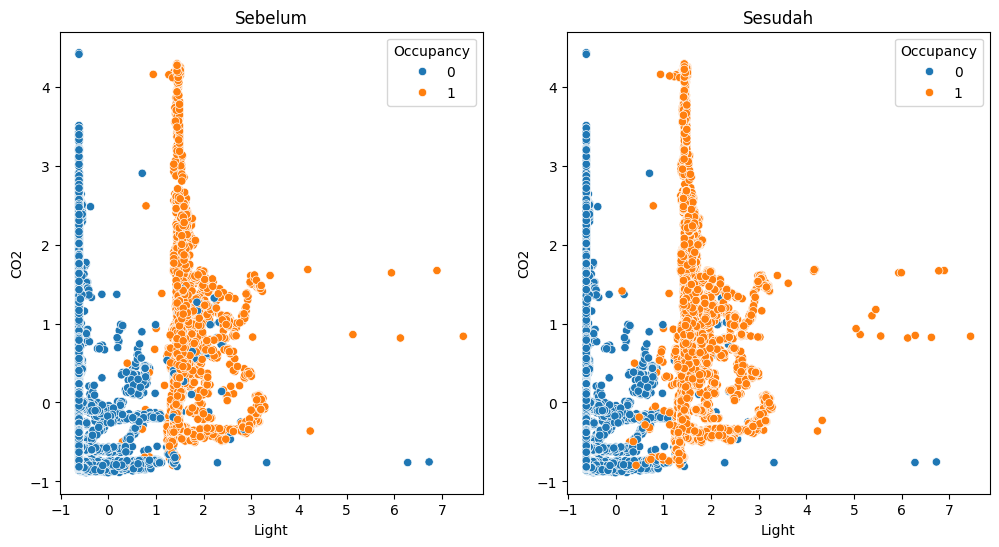

In [ ]:
f, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.scatterplot(x='Light', y='CO2', data=df_sebelum, hue='Occupancy', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='Light', y='CO2', data=df_sesudah, hue='Occupancy', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

Accuracy  0.9905966277561609
Precision  0.9840791678057466
Recall  0.9897227245328512
Confusion matrix  [[4699   41]
 [  17 1411]]


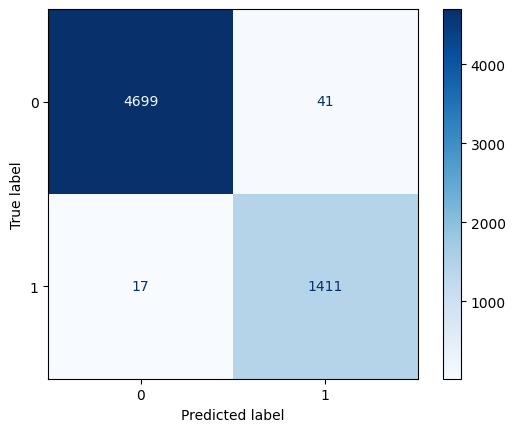

In [ ]:
model=RandomForestClassifier()
model.fit(X_resampled, y_resampled)

# membuat prediksi
y_pred = model.predict(X_test)

#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# plt.show()
disp.plot(cmap=plt.cm.Blues)